# 22 — Overlay Predicted Risk vs Actual FIRMS Points

Notebook ini membuat visualisasi **prediksi grid-cell** versus **titik FIRMS aktual yang presisi**.

## Tujuan
Model final skripsi memprediksi risiko hotspot pada level **grid-cell 0,25°**, bukan pada level titik koordinat persis.  
Karena itu, visualisasi yang benar adalah:

- **kotak/grid** = skor prediksi model untuk `t+1`;
- **titik merah** = deteksi FIRMS aktual pada hari `t+1`.

Dengan cara ini, kita bisa melihat apakah titik api aktual muncul pada area yang diberi skor risiko tinggi oleh model.

## Output utama
Notebook ini akan menghasilkan:

1. **peta harian NodeGRU-L14 vs titik FIRMS aktual**;
2. **peta harian LR13 vs titik FIRMS aktual**;
3. **peta side-by-side LR13 vs NodeGRU-L14**;
4. **tabel ringkasan jumlah titik FIRMS aktual per hari dalam domain T2**.

> Catatan penting: warna grid menunjukkan **risk score**, bukan prediksi koordinat titik api presisi.

In [2]:
# 1. Imports

from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

warnings.filterwarnings("ignore", category=UserWarning)

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 260)

In [3]:
# 2. Resolve project root and required files

cwd = Path.cwd()

candidate_roots = [
    cwd,
    cwd.parent,
    Path("/content/skripsi-karhut"),
    Path("/content/drive/MyDrive/skripsi-karhut"),
]

PROJECT_ROOT = None

for root in candidate_roots:
    pred_candidate = (
        root
        / "model_results"
        / "regional_025_final_test"
        / "t2"
        / "exports"
        / "final_september_predictions.csv"
    )
    if pred_candidate.exists():
        PROJECT_ROOT = root
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate project root with final_september_predictions.csv."
    )

FINAL_PRED_PATH = (
    PROJECT_ROOT
    / "model_results"
    / "regional_025_final_test"
    / "t2"
    / "exports"
    / "final_september_predictions.csv"
)

RAW_FIRE_DIR_CANDIDATES = [
    PROJECT_ROOT / "data" / "kalimantan" / "fire_firms" / "daily",
    PROJECT_ROOT / "KARHUT_Data_Share" / "data" / "kalimantan" / "fire_firms" / "daily",
]

RAW_FIRE_DIR = None

for candidate in RAW_FIRE_DIR_CANDIDATES:
    if candidate.exists() and list(candidate.glob("fires_*.csv")):
        RAW_FIRE_DIR = candidate
        break

if RAW_FIRE_DIR is None:
    matches = []
    for p in PROJECT_ROOT.rglob("fires_*.csv"):
        if "fire_firms" in str(p).lower() and "kalimantan" in str(p).lower():
            matches.append(p.parent)
    if matches:
        RAW_FIRE_DIR = sorted(matches, key=lambda x: len(str(x)))[0]

if RAW_FIRE_DIR is None:
    raise FileNotFoundError(
        "Could not locate raw Kalimantan FIRMS daily folder."
    )

OUTPUT_DIR = (
    PROJECT_ROOT
    / "model_results"
    / "regional_025_final_test"
    / "t2"
    / "figures"
    / "overlay_actual_points"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT :", PROJECT_ROOT)
print("Predictions  :", FINAL_PRED_PATH)
print("Raw FIRMS dir:", RAW_FIRE_DIR)
print("Output dir   :", OUTPUT_DIR)

PROJECT_ROOT : c:\Users\Asus\Documents\skripsi-karhut
Predictions  : c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_final_test\t2\exports\final_september_predictions.csv
Raw FIRMS dir: c:\Users\Asus\Documents\skripsi-karhut\data\raw\kalimantan\fire_firms\hourly
Output dir   : c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_final_test\t2\figures\overlay_actual_points


In [4]:
# 3. Load final September predictions

pred = pd.read_csv(
    FINAL_PRED_PATH,
    parse_dates=["origin_date", "forecast_date"],
)

required_cols = {
    "origin_date",
    "forecast_date",
    "cell_id",
    "grid_lat",
    "grid_lon",
    "y_true",
    "nodegru_l14_score",
    "lr13_score",
}

missing = sorted(required_cols - set(pred.columns))
if missing:
    raise ValueError(f"Missing required prediction columns: {missing}")

pred["cell_id"] = pred["cell_id"].astype(str)

GRID_STEP = 0.25
HALF_STEP = GRID_STEP / 2

domain_bounds = {
    "west": pred["grid_lon"].min() - HALF_STEP,
    "east": pred["grid_lon"].max() + HALF_STEP,
    "south": pred["grid_lat"].min() - HALF_STEP,
    "north": pred["grid_lat"].max() + HALF_STEP,
}

forecast_dates = sorted(pred["forecast_date"].dropna().unique())

print("Prediction rows :", len(pred))
print("Unique cells    :", pred['cell_id'].nunique())
print("Forecast dates  :", len(forecast_dates))
print("Domain bounds   :", domain_bounds)

display(
    pred.head()
)

Prediction rows : 1197
Unique cells    : 133
Forecast dates  : 9
Domain bounds   : {'west': np.float64(113.5), 'east': np.float64(116.75), 'south': np.float64(-4.25), 'north': np.float64(-1.0)}


,origin_date,forecast_date,cell_id,grid_lat,grid_lon,y_true,active_days_prev3_incl_t,is_emerging_eligible,is_emerging_positive,lr13_score,nodegru_l14_score,lr13_flag,nodegru_l14_flag
0,2026-09-01,2026-09-02,regional025_10_22,-1.875,113.625,1,3.0,False,False,0.999992,0.971133,True,True
1,2026-09-01,2026-09-02,regional025_10_23,-1.875,113.875,1,3.0,False,False,1.000000,0.974532,True,True
2,2026-09-01,2026-09-02,regional025_10_24,-1.875,114.125,1,3.0,False,False,1.000000,0.975214,True,True
3,2026-09-01,2026-09-02,regional025_10_25,-1.875,114.375,1,3.0,False,False,1.000000,0.976170,True,True
4,2026-09-01,2026-09-02,regional025_10_26,-1.875,114.625,1,3.0,False,False,0.999994,0.969548,True,True


In [5]:
# 4. FIRMS daily-file utilities

def detect_lat_lon_columns(df):
    candidates = [
        ("lat", "lon"),
        ("latitude", "longitude"),
        ("Latitude", "Longitude"),
        ("LATITUDE", "LONGITUDE"),
    ]

    for lat_col, lon_col in candidates:
        if lat_col in df.columns and lon_col in df.columns:
            return lat_col, lon_col

    lower_map = {c.lower(): c for c in df.columns}
    if "latitude" in lower_map and "longitude" in lower_map:
        return lower_map["latitude"], lower_map["longitude"]
    if "lat" in lower_map and "lon" in lower_map:
        return lower_map["lat"], lower_map["lon"]

    raise ValueError(
        "Could not detect latitude/longitude columns in FIRMS file."
    )


def load_raw_firms_points_for_date(date_value):
    date_value = pd.Timestamp(date_value)
    path = RAW_FIRE_DIR / f"fires_{date_value.date()}.csv"

    if not path.exists():
        print(f"WARNING: raw FIRMS file missing for {date_value.date()}: {path.name}")
        return pd.DataFrame(columns=["lat", "lon", "frp", "file_path"])

    df = pd.read_csv(path)

    if len(df) == 0:
        return pd.DataFrame(columns=["lat", "lon", "frp", "file_path"])

    lat_col, lon_col = detect_lat_lon_columns(df)

    result = df.copy()
    result = result.rename(columns={lat_col: "lat", lon_col: "lon"})

    result["lat"] = pd.to_numeric(result["lat"], errors="coerce")
    result["lon"] = pd.to_numeric(result["lon"], errors="coerce")

    if "frp" in result.columns:
        result["frp"] = pd.to_numeric(result["frp"], errors="coerce")
    else:
        result["frp"] = np.nan

    result = result.dropna(subset=["lat", "lon"]).copy()
    result["file_path"] = str(path)

    return result.reset_index(drop=True)


def subset_points_to_domain(points_df, bounds, padding=0.0):
    if points_df.empty:
        return points_df.copy()

    west = bounds["west"] - padding
    east = bounds["east"] + padding
    south = bounds["south"] - padding
    north = bounds["north"] + padding

    mask = (
        points_df["lon"].between(west, east, inclusive="both")
        &
        points_df["lat"].between(south, north, inclusive="both")
    )

    return points_df.loc[mask].copy().reset_index(drop=True)

In [6]:
# 5. Quick audit of raw actual points per September forecast date

audit_rows = []

for forecast_date in forecast_dates:
    raw_points = load_raw_firms_points_for_date(forecast_date)
    regional_points = subset_points_to_domain(raw_points, domain_bounds, padding=0.0)

    audit_rows.append({
        "forecast_date": pd.Timestamp(forecast_date),
        "raw_points_total_file": len(raw_points),
        "raw_points_inside_T2_domain": len(regional_points),
        "frp_sum_inside_T2": float(regional_points["frp"].sum(skipna=True)) if not regional_points.empty else 0.0,
    })

audit = pd.DataFrame(audit_rows)

display(audit)

,forecast_date,raw_points_total_file,raw_points_inside_T2_domain,frp_sum_inside_T2
0,2026-09-02,4811,985,5191.87
1,2026-09-03,5072,1749,8247.87
2,2026-09-04,3785,1743,9819.73
3,2026-09-05,4212,1568,12679.96
4,2026-09-06,3133,1016,7492.39
5,2026-09-07,1420,417,1569.58
6,2026-09-08,2391,897,3851.17
7,2026-09-09,2081,876,1987.87
8,2026-09-10,2313,674,2641.21


In [7]:
# 6. Plotting helpers

def draw_prediction_grid(ax, day_df, score_col, title_prefix, threshold=None):
    cmap = plt.cm.YlOrRd
    norm = Normalize(vmin=0, vmax=1)

    for row in day_df.itertuples(index=False):
        rect = Rectangle(
            (row.grid_lon - HALF_STEP, row.grid_lat - HALF_STEP),
            GRID_STEP,
            GRID_STEP,
            facecolor=cmap(norm(getattr(row, score_col))),
            edgecolor="grey",
            linewidth=0.35,
            alpha=0.9,
        )
        ax.add_patch(rect)

    if threshold is not None and score_col in day_df.columns:
        flagged = day_df[day_df[score_col] >= threshold]
        for row in flagged.itertuples(index=False):
            rect = Rectangle(
                (row.grid_lon - HALF_STEP, row.grid_lat - HALF_STEP),
                GRID_STEP,
                GRID_STEP,
                facecolor="none",
                edgecolor="black",
                linewidth=1.2,
            )
            ax.add_patch(rect)

    actual_cells = day_df[day_df["y_true"].eq(1)]
    if not actual_cells.empty:
        ax.scatter(
            actual_cells["grid_lon"],
            actual_cells["grid_lat"],
            marker="x",
            s=40,
            linewidths=1.2,
            label="Actual positive cell (t+1)",
        )

    ax.set_title(title_prefix)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_xlim(domain_bounds["west"], domain_bounds["east"])
    ax.set_ylim(domain_bounds["south"], domain_bounds["north"])
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.15)

    sm = ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])
    return sm


def overlay_raw_points(ax, raw_points):
    if raw_points.empty:
        return

    ax.scatter(
        raw_points["lon"],
        raw_points["lat"],
        s=22,
        alpha=0.9,
        label="Raw FIRMS point",
    )


def add_stats_text(ax, day_df, raw_points, score_col):
    positives = int(day_df["y_true"].sum())
    mean_score = float(day_df[score_col].mean())
    max_score = float(day_df[score_col].max())

    lines = [
        f"Grid cells: {len(day_df)}",
        f"Positive cells: {positives}",
        f"Raw FIRMS points: {len(raw_points)}",
        f"Mean score: {mean_score:.3f}",
        f"Max score: {max_score:.3f}",
    ]

    ax.text(
        1.02,
        0.98,
        "\n".join(lines),
        transform=ax.transAxes,
        va="top",
        ha="left",
        fontsize=9,
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.85),
    )

In [8]:
# 7. Single-day plotting functions

def make_single_model_map(
    forecast_date,
    model_col="nodegru_l14_score",
    model_name="NodeGRU-L14",
    threshold=None,
    show=True,
    save=True,
):
    forecast_date = pd.Timestamp(forecast_date)

    day_df = (
        pred[pred["forecast_date"].eq(forecast_date)]
        .copy()
        .sort_values(["grid_lat", "grid_lon"])
    )

    if day_df.empty:
        raise ValueError(f"No prediction rows found for {forecast_date.date()}")

    origin_date = pd.Timestamp(day_df["origin_date"].iloc[0])

    raw_points = load_raw_firms_points_for_date(forecast_date)
    raw_points = subset_points_to_domain(raw_points, domain_bounds)

    fig, ax = plt.subplots(figsize=(8.6, 7.2))

    sm = draw_prediction_grid(
        ax,
        day_df,
        score_col=model_col,
        title_prefix=f"{model_name}: forecast made {origin_date.date()} → actual {forecast_date.date()}",
        threshold=threshold,
    )
    overlay_raw_points(ax, raw_points)
    add_stats_text(ax, day_df, raw_points, model_col)

    cbar = plt.colorbar(sm, ax=ax)
    cbar.set_label(f"{model_name} risk score")

    handles, labels = ax.get_legend_handles_labels()
    if handles:
        ax.legend(loc="upper left")

    plt.tight_layout()

    save_path = None
    if save:
        save_path = OUTPUT_DIR / f"{model_name.lower().replace('-', '').replace(' ', '_')}_{forecast_date.date()}_overlay.png"
        plt.savefig(save_path, dpi=180, bbox_inches="tight")

    if show:
        plt.show()
    else:
        plt.close(fig)

    return save_path

In [9]:
# 8. Side-by-side comparison function: LR13 vs NodeGRU-L14

def make_side_by_side_map(
    forecast_date,
    lr_threshold=None,
    gru_threshold=None,
    show=True,
    save=True,
):
    forecast_date = pd.Timestamp(forecast_date)

    day_df = (
        pred[pred["forecast_date"].eq(forecast_date)]
        .copy()
        .sort_values(["grid_lat", "grid_lon"])
    )

    if day_df.empty:
        raise ValueError(f"No prediction rows found for {forecast_date.date()}")

    origin_date = pd.Timestamp(day_df["origin_date"].iloc[0])

    raw_points = load_raw_firms_points_for_date(forecast_date)
    raw_points = subset_points_to_domain(raw_points, domain_bounds)

    fig, axes = plt.subplots(1, 2, figsize=(15.5, 7.0), sharex=True, sharey=True)

    sm_left = draw_prediction_grid(
        axes[0],
        day_df,
        score_col="lr13_score",
        title_prefix=f"LR13: {origin_date.date()} → {forecast_date.date()}",
        threshold=lr_threshold,
    )
    overlay_raw_points(axes[0], raw_points)
    add_stats_text(axes[0], day_df, raw_points, "lr13_score")

    sm_right = draw_prediction_grid(
        axes[1],
        day_df,
        score_col="nodegru_l14_score",
        title_prefix=f"NodeGRU-L14: {origin_date.date()} → {forecast_date.date()}",
        threshold=gru_threshold,
    )
    overlay_raw_points(axes[1], raw_points)
    add_stats_text(axes[1], day_df, raw_points, "nodegru_l14_score")

    cbar_left = plt.colorbar(sm_left, ax=axes[0], fraction=0.046, pad=0.04)
    cbar_left.set_label("LR13 risk score")

    cbar_right = plt.colorbar(sm_right, ax=axes[1], fraction=0.046, pad=0.04)
    cbar_right.set_label("NodeGRU-L14 risk score")

    for ax in axes:
        handles, labels = ax.get_legend_handles_labels()
        if handles:
            ax.legend(loc="upper left")

    fig.suptitle(
        f"Predicted grid risk vs raw FIRMS points — {forecast_date.date()}",
        y=1.02,
        fontsize=14,
    )

    plt.tight_layout()

    save_path = None
    if save:
        save_path = OUTPUT_DIR / f"side_by_side_lr13_vs_nodegru_{forecast_date.date()}.png"
        plt.savefig(save_path, dpi=180, bbox_inches="tight")

    if show:
        plt.show()
    else:
        plt.close(fig)

    return save_path

In [10]:
# 9. Optional thresholds to outline predicted-positive cells
# If you want no black outline boxes, keep them as None.

LR13_THRESHOLD = None
NODEGRU_THRESHOLD = None

print("Threshold overlays:")
print("LR13 threshold     :", LR13_THRESHOLD)
print("NodeGRU threshold  :", NODEGRU_THRESHOLD)

Threshold overlays:
LR13 threshold     : None
NodeGRU threshold  : None


Preview date: 2026-09-02


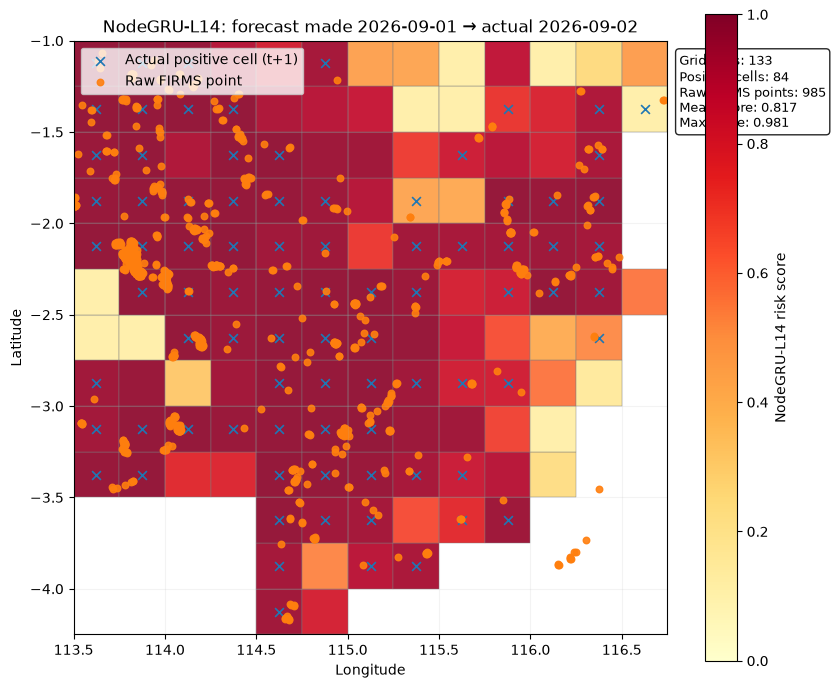

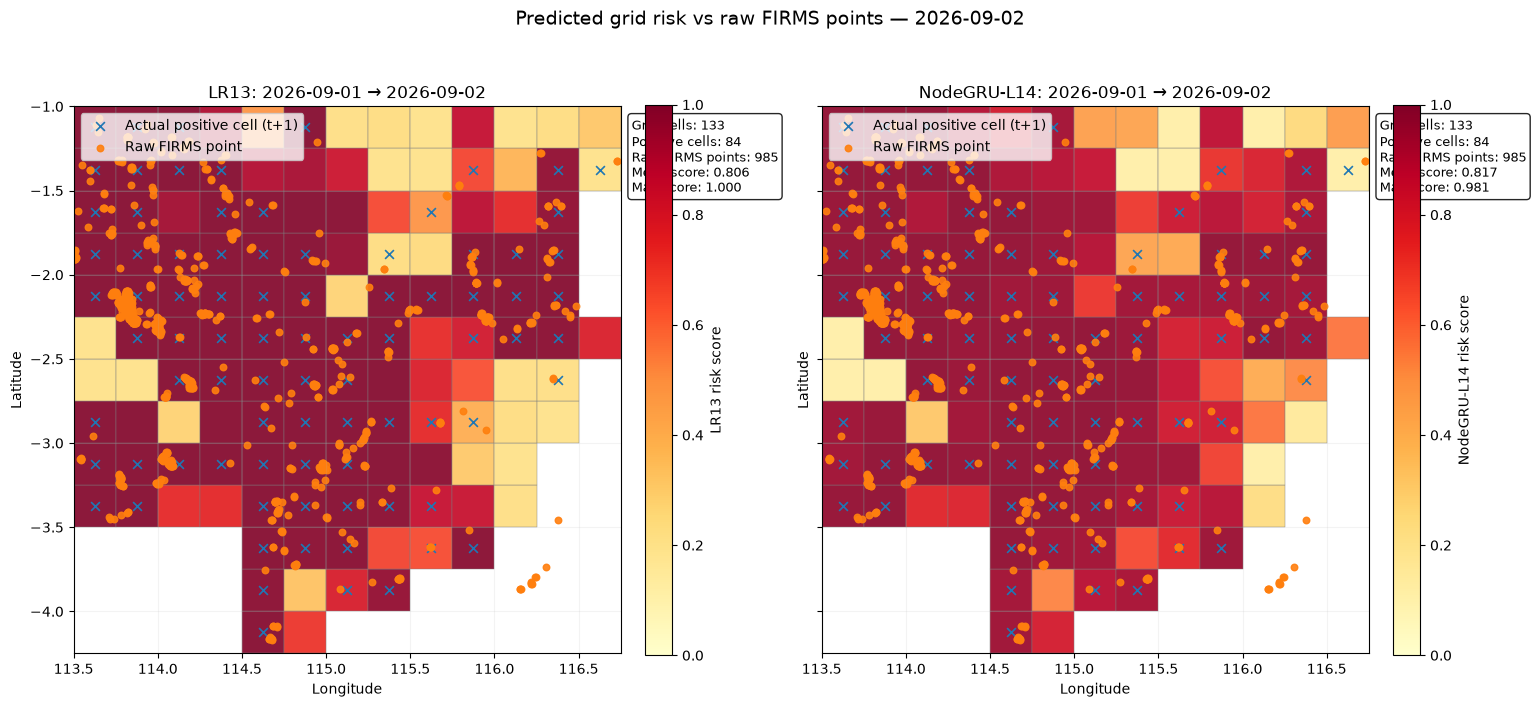

In [11]:
# 10. Example preview for one date
# Change the date below if you want another forecast date.

preview_date = forecast_dates[0]

print("Preview date:", pd.Timestamp(preview_date).date())

_ = make_single_model_map(
    preview_date,
    model_col="nodegru_l14_score",
    model_name="NodeGRU-L14",
    threshold=NODEGRU_THRESHOLD,
    show=True,
    save=False,
)

_ = make_side_by_side_map(
    preview_date,
    lr_threshold=LR13_THRESHOLD,
    gru_threshold=NODEGRU_THRESHOLD,
    show=True,
    save=False,
)

In [12]:
# 11. Export ALL daily overlay maps

nodegru_paths = []
lr_paths = []
compare_paths = []

for forecast_date in forecast_dates:
    forecast_date = pd.Timestamp(forecast_date)

    path_gru = make_single_model_map(
        forecast_date,
        model_col="nodegru_l14_score",
        model_name="NodeGRU-L14",
        threshold=NODEGRU_THRESHOLD,
        show=False,
        save=True,
    )
    nodegru_paths.append(path_gru)

    path_lr = make_single_model_map(
        forecast_date,
        model_col="lr13_score",
        model_name="LR13",
        threshold=LR13_THRESHOLD,
        show=False,
        save=True,
    )
    lr_paths.append(path_lr)

    path_compare = make_side_by_side_map(
        forecast_date,
        lr_threshold=LR13_THRESHOLD,
        gru_threshold=NODEGRU_THRESHOLD,
        show=False,
        save=True,
    )
    compare_paths.append(path_compare)

print("Saved NodeGRU maps :", len(nodegru_paths))
print("Saved LR13 maps    :", len(lr_paths))
print("Saved compare maps :", len(compare_paths))
print("Output folder      :", OUTPUT_DIR)

Saved NodeGRU maps : 9
Saved LR13 maps    : 9
Saved compare maps : 9
Output folder      : c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_final_test\t2\figures\overlay_actual_points


In [13]:
# 12. Summary table per day for thesis/report

summary_rows = []

for forecast_date in forecast_dates:
    forecast_date = pd.Timestamp(forecast_date)
    day_df = pred[pred["forecast_date"].eq(forecast_date)].copy()
    raw_points = load_raw_firms_points_for_date(forecast_date)
    raw_points = subset_points_to_domain(raw_points, domain_bounds)

    summary_rows.append({
        "forecast_date": forecast_date,
        "origin_date": pd.Timestamp(day_df["origin_date"].iloc[0]),
        "n_grid_cells": len(day_df),
        "n_positive_cells": int(day_df["y_true"].sum()),
        "n_raw_firms_points_in_T2": int(len(raw_points)),
        "nodegru_mean_score": float(day_df["nodegru_l14_score"].mean()),
        "nodegru_max_score": float(day_df["nodegru_l14_score"].max()),
        "lr13_mean_score": float(day_df["lr13_score"].mean()),
        "lr13_max_score": float(day_df["lr13_score"].max()),
    })

summary = pd.DataFrame(summary_rows)

display(summary)

,forecast_date,origin_date,n_grid_cells,n_positive_cells,n_raw_firms_points_in_T2,nodegru_mean_score,nodegru_max_score,lr13_mean_score,lr13_max_score
0,2026-09-02,2026-09-01,133,84,985,0.816855,0.981261,0.806093,1.0
1,2026-09-03,2026-09-02,133,91,1749,0.814037,0.981024,0.781049,1.0
2,2026-09-04,2026-09-03,133,84,1743,0.807602,0.982064,0.776906,1.0
3,2026-09-05,2026-09-04,133,81,1568,0.806720,0.982995,0.766613,1.0
4,2026-09-06,2026-09-05,133,91,1016,0.792318,0.982707,0.756039,1.0
5,2026-09-07,2026-09-06,133,52,417,0.792313,0.983047,0.758276,1.0
6,2026-09-08,2026-09-07,133,72,897,0.775353,0.981561,0.685682,1.0
7,2026-09-09,2026-09-08,133,65,876,0.762966,0.980188,0.694801,1.0
8,2026-09-10,2026-09-09,133,64,674,0.742674,0.981175,0.653784,1.0


In [14]:
# 13. Save summary CSV

summary_path = OUTPUT_DIR / "overlay_map_daily_summary.csv"
summary.to_csv(summary_path, index=False)

print("Saved summary:", summary_path)

Saved summary: c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_final_test\t2\figures\overlay_actual_points\overlay_map_daily_summary.csv


## Cara membaca visualisasi

- **Kotak berwarna** = risk score per grid-cell.
- **Semakin gelap/merah** = model memberi risiko lebih tinggi untuk hari berikutnya.
- **Titik FIRMS merah** = deteksi aktual pada hari target.
- Kalau banyak titik FIRMS jatuh di area/grid berwarna lebih tinggi, berarti model membantu mengarahkan perhatian ke area yang relevan.

## Catatan metodologis
Visualisasi ini hanya untuk interpretasi hasil.  
Model tetap bekerja pada level **grid-cell**, sehingga titik FIRMS presisi digunakan sebagai **overlay observasi aktual**, bukan target prediksi langsung.